## Transition Matrix using CellRank

#### By: Josh Navarro


In [1]:
# Imports that we will be using.

from pathlib import Path

import numpy as np
import scvelo as scv
import torch

from deepvelo.utils import(
    velocity,
    velocity_confidence, 
    latent_time,
    update_dict,
    save_model_and_config,
    cross_boundary_correctness,
)
from deepvelo.utils.preprocess import autoset_coeff_s
from deepvelo.utils.plot import statplot, compare_plot
from deepvelo import train, Constants

# For the reproducibility
SEED = 123
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
np.random.seed(SEED)

scv.settings.verbosity = 3  # show errors(0), warnings(1), info(2), hints(3)
scv.settings.set_figure_params(
    "scvelo", transparent=False
)
%load_ext autoreload
%autoreload 2

c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\deepvelo\utils\plot.py:5: DeprecationWarning: deepvelo.utils.plot is deprecated. Please use deepvelo.plot.plot instead.
  warnings.warn(


In [17]:
#adata = scv.read(r"C:\Users\joshu\Desktop\RNA_Velocity_R\DeepVelo\Figure_2_Follow\human_cd34_bone_marrow.h5ad", cache = True)\
adata = scv.read(r"c:\Users\joshu\Desktop\RNA_Velocity_R\veloVI-20260709T175737Z-2-001\janssens_2025_CellRanger_Velocyto_counts_eLNP.h5ad")
scv.pp.filter_and_normalize(adata, min_shared_counts=20, n_top_genes=2000) # Filters and nomalizes the data
scv.pp.moments(adata, n_neighbors=30, n_pcs=30)

c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\anndata\__init__.py:55: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(


Filtered out 23855 genes that are detected 20 counts (shared).


c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\scvelo\preprocessing\utils.py:524: RuntimeWarning: invalid value encountered in sqrt
  return nom / np.sqrt(denom_x * denom_y)


Normalized count data: X, spliced, unspliced.
Extracted 2000 highly variable genes.
Logarithmized X.
computing neighbors
    finished (0:00:09) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:05) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)


In [18]:
# The confiugurations for the DeepVelo
configs = {
    "name" : "DeepVelo",
    "loss" : {"args": {"coeff_s": 0.5}},
    "trainer" : {"verbosity": 0},
}
configs = update_dict(Constants.default_configs, configs)

In [19]:
velocity(adata, mask_zero = False)
trainer = train(adata, configs)

computing velocities
    finished (0:00:06) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
Config Warning: Set to use GPU, but GPU version of DGL is not installed. Reset to use CPU instead.
building graph


c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\dgl\base.py:45: DGLWarning: Recommend creating graphs by `dgl.graph(data)` instead of `dgl.DGLGraph(data)`.
  return warnings.warn(message, category=category, stacklevel=1)
INFO:train:Beginning training of DeepVelo ...


velo data shape: torch.Size([21327, 2000])


c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\torch\amp\autocast_mode.py:198: UserWarning: User provided device_type of 'cuda', but CUDA is not available. Disabling
  warnings.warn('User provided device_type of \'cuda\', but CUDA is not available. Disabling')


confidence mse shape: (21327, 2000)
confidence mse stats: max 21647.92578125, min 0.0, mean 0.5897024869918823, std 11.597043991088867
confidence corr shape: (2000,)
confidence corr stats: max 0.8732717633247375, min -0.5089890360832214, mean 0.5579906105995178, std 0.13508795201778412
velo_mat shape: (21327, 2000)
--> added 'velocity' (adata.layers)
--> added 'velocity_unspliced' (adata.layers)
--> added 'cell_specific_beta' (adata.layers)
--> added 'cell_specific_gamma' (adata.layers)


In [31]:
# Save the trained data for jenson
adata.write_h5ad("jenson_deepvelo_trained.h5ad")

In [20]:
# Create the velocities
scv.tl.velocity_graph(adata, n_jobs = 4)

computing velocity graph (using 4/8 cores)


  0%|          | 0/21327 [00:00<?, ?cells/s]

c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\scvelo\core\_parallelize.py:138: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  res = np.array(res) if as_array else res


    finished (0:00:55) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)


In [33]:
#print(adata)
adata.obs["Celltype"]

KeyError: 'Celltype'

In [24]:
scv.tl.tsne(adata)

c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\scvelo\plotting\utils.py:555: FutureWarning: Setting categories in-place is deprecated and will raise in a future version. Use rename_categories instead.
  obs_vals.cat.categories = obs_vals.cat.categories.astype(str)


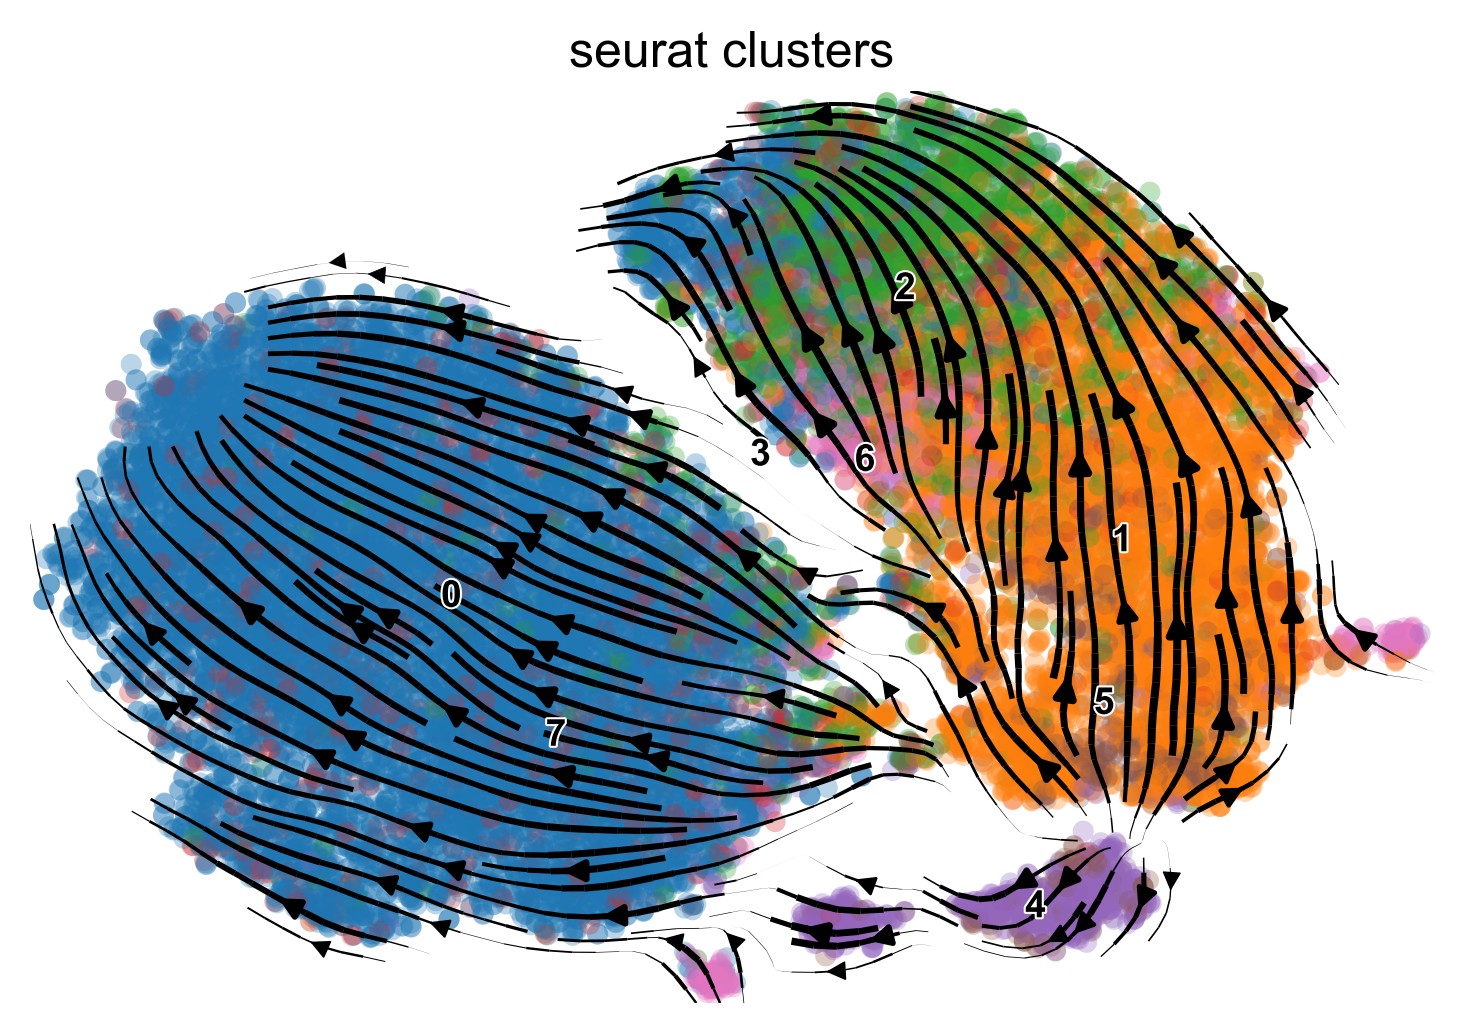

In [29]:
# Velocity Plot
scv.pl.velocity_embedding_stream(
    adata,
    basis="tsne",
    color="seurat_clusters",
    legend_fontsize=9,
    dpi=150,
)

computing terminal states
    identified 5 regions of root cells and 1 region of end points .
    finished (0:00:02) --> added
    'root_cells', root cells of Markov diffusion process (adata.obs)
    'end_points', end points of Markov diffusion process (adata.obs)
computing latent time using root_cells as prior


c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\deepvelo\utils\temporal.py:803: DeprecationWarning: `np.float` is a deprecated alias for the builtin `float`. To silence this warning, use `float` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.float64` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  idx_roots = idx_roots.astype(np.float) > 1 - 1e-3


    finished (0:00:02) --> added 
    'latent_time', shared time (adata.obs)


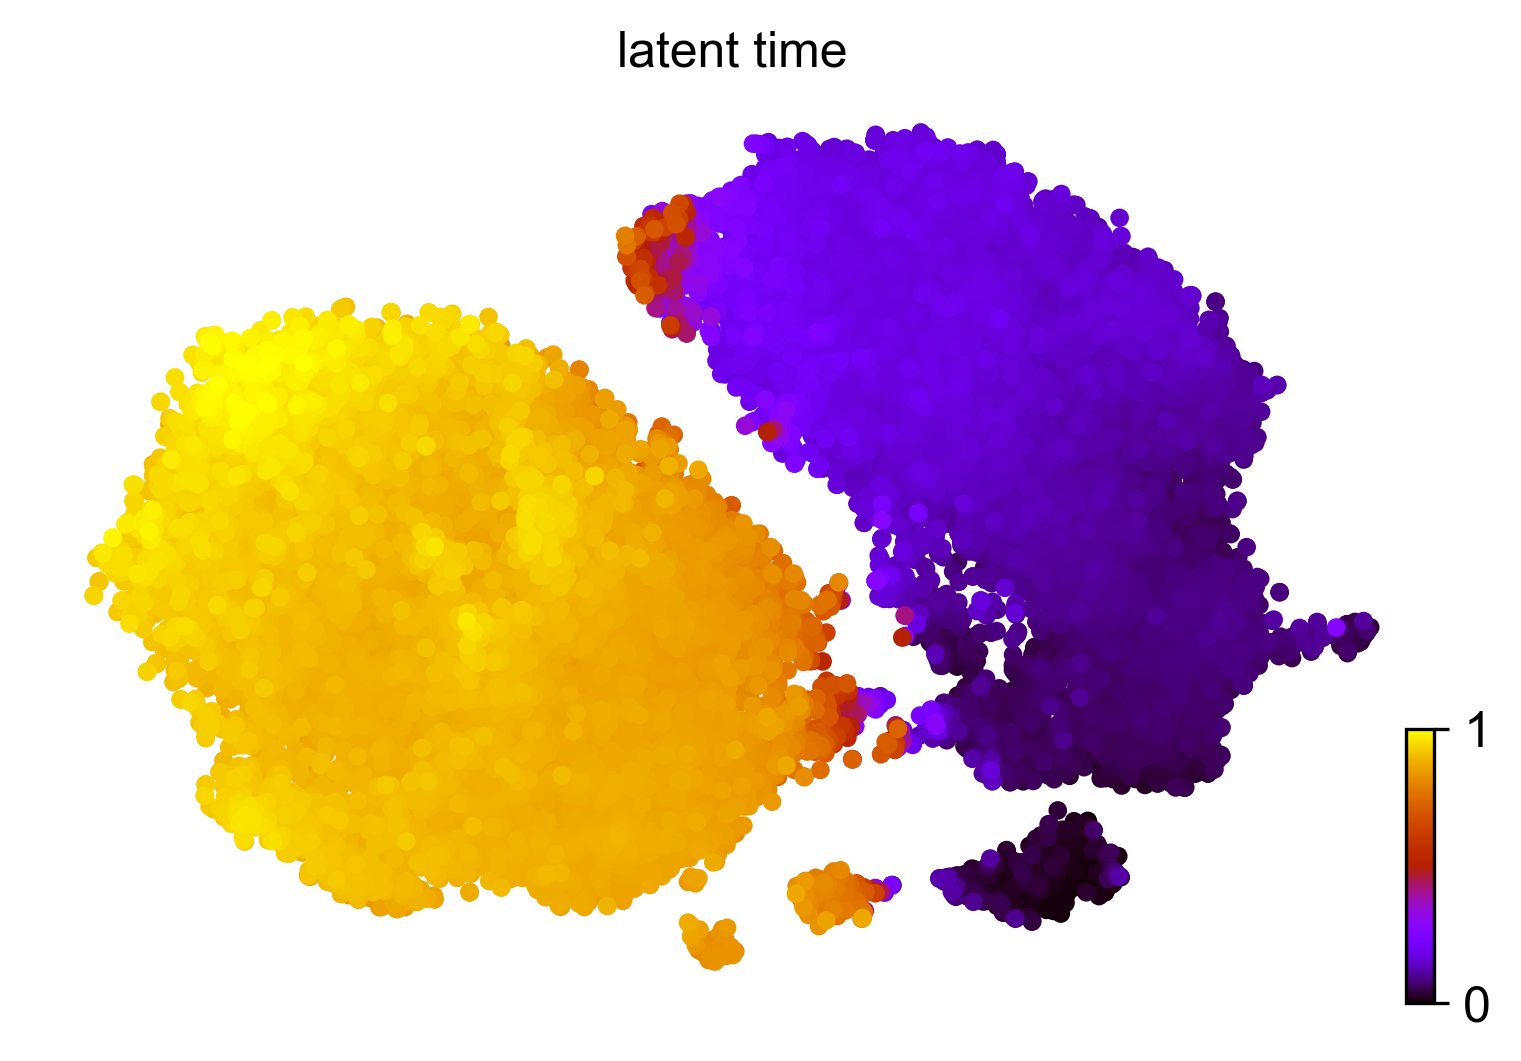

In [26]:
# Psuedo Time Plots
latent_time(adata)
scv.pl.scatter(
    adata,
    color="latent_time",
    color_map="gnuplot",
    size=80,
    dpi=150,
)

running PAGA using priors: ['velocity_pseudotime']


c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\scvelo\tools\paga.py:144: RuntimeWarning: overflow encountered in long_scalars
  reference = np.sqrt(total_n[i] * total_n[j])
c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\scvelo\tools\paga.py:144: RuntimeWarning: invalid value encountered in sqrt
  reference = np.sqrt(total_n[i] * total_n[j])
c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\scvelo\tools\paga.py:150: RuntimeWarning: invalid value encountered in divide
  threshold = max(np.nanmin(np.nanmax(T / (T > 0), axis=0)) - 1e-6, 0.01)
c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\scvelo\tools\paga.py:150: RuntimeWarning: All-NaN slice encountered
  threshold = max(np.nanmin(np.nanmax(T / (T > 0), axis=0)) - 1e-6, 0.01)
c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\scvelo\tools\paga.py:176: RuntimeWarning: invalid value encountered in divide
  self.threshold = np.nanmin(np.nanmax(df.values / (df.values > 0), a

    finished (0:00:02) --> added
    'paga/connectivities', connectivities adjacency (adata.uns)
    'paga/connectivities_tree', connectivities subtree (adata.uns)
    'paga/transitions_confidence', velocity transitions (adata.uns)


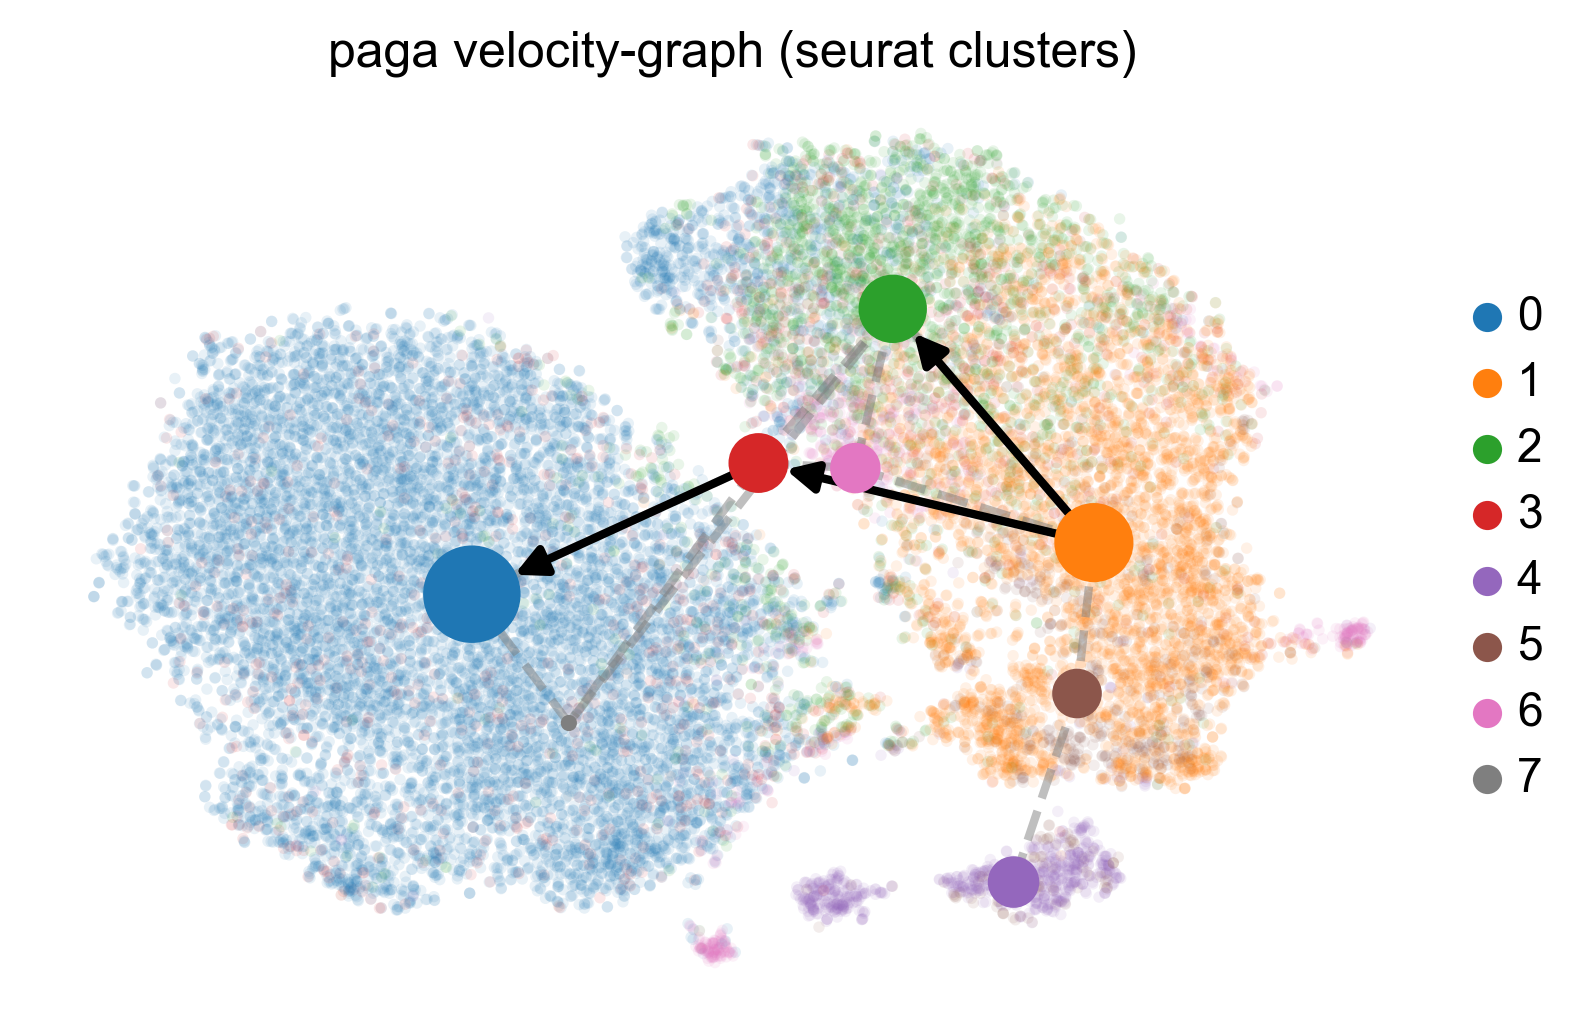

In [30]:
# The Tranjectory Inference
adata.uns["neighbors"]["distances"] = adata.obsp["distances"]
adata.uns["neighbors"]["connectivities"] = adata.obsp["connectivities"]
scv.tl.paga(adata, groups = "seurat_clusters")
scv.pl.paga(
    adata, 
    basis = "tsne",
    size = 30,
    alpha = 0.1,
    min_edge_width = 2,
    node_size_scale = 1,
    dpi = 150,
)